# Verificação Facial com CNN: ResNet50 + ArcFace
### Projeto Final de Biometria (UTFPR Ponta Grossa): treino no **CFP-FP**, teste cruzado no **LFW**

Este notebook faz **o projeto inteiro, do zero**, e explica cada passo. A ideia é que você consiga ler de cima para baixo, entender o que cada célula faz e, no fim, ter todos os resultados que o artigo pede.

**Mapa do que vamos fazer**

| Parte | O que acontece | Onde o artigo usa |
|---|---|---|
| 1 | Entender como os datasets estão organizados e como ler os dados | Base de dados |
| 2 | Montar o **protocolo** (treino / validação / teste, pares genuínos e impostores) | Protocolo experimental |
| 3 | **Pré-processar** as imagens (detectar, alinhar, recortar) | Metodologia |
| 4 | Transformar imagens em tensores para a rede (Dataset e DataLoader) | Metodologia |
| 5 | Construir o **modelo** (ResNet50 + embedding + ArcFace) | Metodologia |
| 6 | Entender **embeddings, cosseno, threshold e métricas** | Metodologia / Resultados |
| 7 | **Treinar** (fine-tuning) | Metodologia |
| 8 | **Avaliar** no teste do CFP-FP | Resultados |
| 9 | **Cross-dataset**: avaliar no LFW sem retreinar | Resultados |
| 10 | **Robustez**: blur e oclusão | Resultados |
| 11 | **Ablação**: o que muda sem o alinhamento | Análise |
| 12 | **Análise de erros** | Análise e discussão |
| 13 | Eficiência computacional e tabela final | Resultados |

> **Como usar:** rode as células na ordem (Shift+Enter). Só a célula de **Configuração** (Parte 0) precisa de ajuste por você: os caminhos dos datasets.

## Parte 0: a ideia por trás de tudo (leia antes de rodar)

**O problema.** *Verificação biométrica* responde a uma pergunta de sim/não: *"estas duas fotos são da mesma pessoa?"* Isso é diferente de *identificação* (descobrir **quem** é). A rede **não** dá o nome da pessoa.

**Como a rede ajuda.** Uma CNN transforma cada foto em uma lista de números, o **embedding** (aqui, 512 números). Pense nele como o "endereço" do rosto em um mapa de 512 dimensões: fotos da mesma pessoa devem morar **perto**, fotos de pessoas diferentes devem morar **longe**.

**Como decidimos.** Para um par de fotos:

1. calculamos o embedding de cada uma;
2. medimos a proximidade com a **similaridade de cosseno** (1 = idênticos, 0 = sem relação);
3. comparamos com um **limiar (threshold)**: acima dele dizemos *"mesma pessoa"* (genuíno), abaixo dizemos *"pessoas diferentes"* (impostor).

**Como ensinamos a rede a gerar bons endereços.** Usamos a loss **ArcFace**: durante o treino a rede tenta *classificar* as pessoas do conjunto de treino, mas com uma "margem" extra que obriga rostos da mesma pessoa a ficarem bem agrupados. Depois do treino **jogamos fora o classificador** e ficamos só com o embedding. Isso é o que o enunciado pede (nada de classificador direto).

**Duas regras de ouro do enunciado (vamos respeitá-las no código):**

- A divisão treino/validação/teste é **por identidade**, nunca por imagem. Uma pessoa que aparece no treino **não pode** aparecer no teste.
- O threshold é escolhido **só na validação**, depois **congelado**. O teste só é usado no final.

In [1]:
# Instala o que o Colab não traz pronto (torch, numpy, pandas, sklearn e matplotlib já vêm instalados)
%pip install -q opencv-python-headless tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Importações: cada biblioteca tem um papel
import os, re, json, math, time, random, platform, urllib.request
from pathlib import Path

import numpy as np                      # contas com vetores/matrizes
import pandas as pd                     # tabelas (CSV)
import cv2                              # OpenCV: ler imagens, detectar rosto, alinhar
import matplotlib.pyplot as plt         # gráficos e imagens
from PIL import Image, ImageFilter, ImageDraw   # abrir imagens e aplicar blur/oclusão
from tqdm.auto import tqdm              # barra de progresso

import torch                            # PyTorch: redes neurais
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms   # ResNet50 pronta e transformações de imagem

from sklearn.metrics import roc_curve, roc_auc_score   # curva ROC e AUC

print("PyTorch:", torch.__version__)

c:\Users\gusta\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm-4.67.1-py3.12.egg\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.5.1+cu121


### Configuração (a única célula que você precisa editar)

Se estiver no **Google Colab**, a célula abaixo monta o seu Google Drive para que datasets, checkpoints e resultados **não se percam** se a sessão cair. Se estiver rodando na sua máquina, ela é ignorada.

Organize os datasets assim (nomes das pastas podem ser outros, é só ajustar `CFP_RAW`, `LFW_RAW` e `LFW_CSV`):

```
Projeto_Biometria/
├── data/
│   ├── cfp-dataset/          <- contém Data/ e Protocol/ (os Pair_list_F.txt e Pair_list_P.txt ficam em Protocol/Split/)
│   ├── lfw/                  <- contém DIRETAMENTE uma pasta por pessoa (Aaron_Eckhart/, Abba_Eban/, ...)
│   └── (CSVs do LFW)         <- matchpairsDevTest.csv e mismatchpairsDevTest.csv: o notebook procura sozinho dentro de data/
└── saidas/                   <- o notebook cria: protocols/, processed/, results/, checkpoints/
```

> **Atenção (LFW):** `LFW_RAW` deve apontar para a pasta **que contém diretamente** as pastas das pessoas. Se, ao descompactar, surgir uma pasta dupla (`lfw/lfw/...`), aponte para a de dentro. Os dois CSVs de pares do LFW vêm no mesmo download das imagens (Kaggle); não precisam ficar em um lugar específico, desde que estejam em algum lugar dentro de `DATA_ROOT`.

In [3]:
# ===================== 1) CAMINHOS (ajuste aqui) =====================
DATA_ROOT = Path.cwd() / "data"
WORK_DIR  = Path.cwd() / "saidas"
WORK_DIR.mkdir(parents=True, exist_ok=True)

CFP_RAW = DATA_ROOT / "cfp-dataset"        # contém Data/ e Protocol/
LFW_RAW = DATA_ROOT / "lfw" / "lfw-deepfunneled" / "lfw-deepfunneled"                # pasta que contém DIRETAMENTE uma subpasta por pessoa (Aaron_Eckhart/, ...)
LFW_CSV = DATA_ROOT                        # onde procurar os CSVs de pares do LFW (o notebook acha sozinho)

PROTO_DIR  = WORK_DIR / "protocols"        # listas de treino/validação/teste e pares
PROC_DIR   = WORK_DIR / "processed"        # imagens já alinhadas e recortadas
RES_DIR    = WORK_DIR / "results"          # métricas, scores e gráficos
CKPT_DIR   = WORK_DIR / "checkpoints"      # pesos do modelo treinado
MODELS_DIR = WORK_DIR / "models"           # detector de rosto (YuNet)
for d in (PROTO_DIR, PROC_DIR, RES_DIR, CKPT_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

CFP_PROC = PROC_DIR / "cfp_fp"             # imagens processadas do CFP
LFW_PROC = PROC_DIR / "lfw"                # imagens processadas do LFW

# ===================== 2) HIPERPARÂMETROS =====================
SEED          = 42        # semente: garante que o experimento seja reprodutível
IMAGE_SIZE    = 112       # lado (px) da imagem de entrada da rede
EMBEDDING_DIM = 512       # tamanho do embedding
DROPOUT       = 0.4
PRETRAINED    = True      # True = começa com pesos treinados na ImageNet (baixa ~100 MB na 1ª vez)
FREEZE_LAYERS = ["conv1", "bn1", "layer1", "layer2"]   # camadas congeladas (não treinam)

ARC_SCALE, ARC_MARGIN = 30.0, 0.5   # parâmetros do ArcFace
LEARNING_RATE   = 1e-4
HEAD_LR_MULT    = 10      # a cabeça nova aprende 10x mais rápido que o backbone
WEIGHT_DECAY    = 5e-4
BATCH_SIZE = 32
EPOCHS = 20
PATIENCE = 4              # early stopping: para se a validação não melhorar por 4 épocas
NUM_WORKERS = 0           # use 0 se der erro de multiprocessing (Windows)
RETRAIN = False           # False = se já existir checkpoint, pula o treino

# Protocolo do CFP-FP: os 10 folds oficiais (disjuntos por identidade) divididos assim:
TRAIN_FOLDS, VAL_FOLDS, TEST_FOLDS = [1, 2, 3, 4, 5, 6], [7, 8], [9, 10]

# Pré-processamento
YUNET_URL = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
YUNET_PATH = MODELS_DIR / "face_detection_yunet_2023mar.onnx"
DETECT_SCORE = 0.6        # confiança mínima do detector
REQUIRE_DETECTOR = True   # True = exige o detector (se não baixar, para com aviso)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # normalização da ImageNet
INFERENCE_RUNS = 50       # repetições para medir o tempo de inferência

# Robustez (4 níveis: original, baixa, média, alta)
BLUR_SIGMAS = [0, 1.5, 3.0, 5.0]
OCCLUSION_FRACS = [0.0, 0.2, 0.35, 0.5]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "sem GPU (vai ficar lento; no Colab ative: Ambiente de execução > Alterar tipo > GPU)")

Dispositivo: cuda | NVIDIA GeForce RTX 3050 Ti Laptop GPU


---
# Parte 1: Como os datasets estão organizados e como os dados são lidos

## 1.1 CFP (usaremos o CFP-FP)

O CFP tem **500 celebridades**, cada uma com **10 fotos frontais** e **4 de perfil**. Estrutura:

```
cfp-dataset/
├── Data/
│   ├── Images/<id>/frontal/01.jpg ... 10.jpg
│   ├── Images/<id>/profile/01.jpg ... 04.jpg
│   ├── Fiducials/...                 (landmarks; não vamos usar)
│   └── list_name.txt                 (nomes das 500 pessoas; não vamos usar)
└── Protocol/
    └── Split/
        ├── FF/01 ... 10/ {same.txt, diff.txt}   <- pares frontal-frontal (não usamos)
        ├── FP/01 ... 10/ {same.txt, diff.txt}   <- pares frontal-perfil (o CFP-FP que usamos)
        ├── Pair_list_F.txt   <- "tradutor": número (1..5000) -> caminho da foto frontal
        └── Pair_list_P.txt   <- "tradutor": número (1..2000) -> caminho da foto de perfil
```

Vamos primeiro **olhar** o que existe, sem processar nada.

In [4]:
IMAGES_DIR = CFP_RAW / "Data" / "Images"
print("A pasta do CFP existe?", CFP_RAW.exists(), "|", CFP_RAW)

# Cada subpasta de Images/ é UMA pessoa (identidade)
identities = sorted(p.name for p in IMAGES_DIR.iterdir() if p.is_dir())
n_front = len(list(IMAGES_DIR.glob("*/frontal/*.jpg")))
n_prof  = len(list(IMAGES_DIR.glob("*/profile/*.jpg")))
print(f"Identidades: {len(identities)}  (exemplos: {identities[:5]})")
print(f"Fotos frontais: {n_front}  | Fotos de perfil: {n_prof}")

A pasta do CFP existe? True | c:\Users\gusta\Desktop\Projeto_Biometria\data\cfp-dataset
Identidades: 500  (exemplos: ['001', '002', '003', '004', '005'])
Fotos frontais: 5000  | Fotos de perfil: 2000


### Como uma imagem é lida

O OpenCV (`cv2.imread`) lê a imagem como uma matriz de números (altura × largura × 3 canais). **Cuidado:** ele devolve os canais na ordem **B, G, R** (azul, verde, vermelho), enquanto o matplotlib e o PIL esperam **R, G, B**. Por isso convertemos com `cv2.cvtColor`. Se esquecer, o rosto fica com a pele azulada.

Formato da 1ª imagem (altura, largura, canais): (189, 151, 3) | tipo: uint8


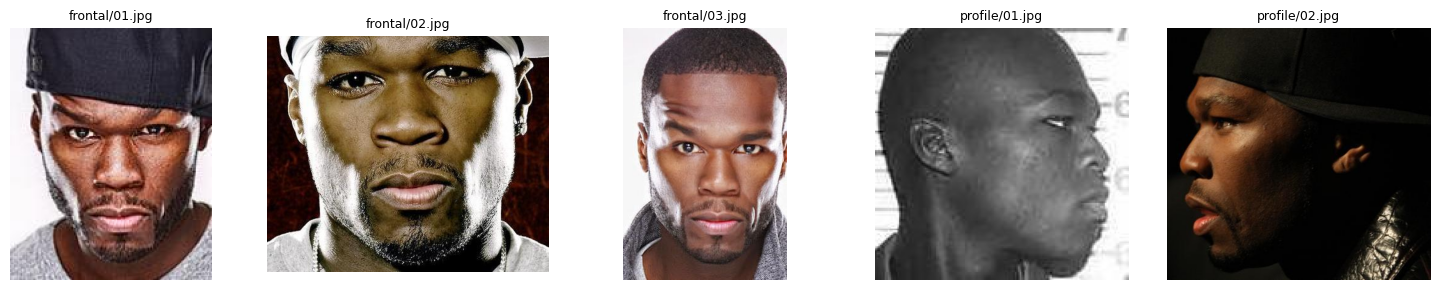

In [5]:
def read_rgb(path):
    """Lê uma imagem do disco e devolve uma matriz RGB (altura, largura, 3) com valores 0..255."""
    bgr = cv2.imread(str(path))
    if bgr is None:
        raise FileNotFoundError(f"Não consegui ler a imagem: {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def show_images(imgs, titles=None, cols=4, size=3):
    rows = math.ceil(len(imgs) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    for ax in np.array(axes).ravel():
        ax.axis("off")
    for ax, im, i in zip(np.array(axes).ravel(), imgs, range(len(imgs))):
        ax.imshow(im)
        if titles: ax.set_title(titles[i], fontsize=9)
    plt.tight_layout(); plt.show()

# Fotos de uma pessoa: 3 frontais e 2 de perfil
pid = identities[0]
paths = sorted((IMAGES_DIR / pid / "frontal").glob("*.jpg"))[:3] + sorted((IMAGES_DIR / pid / "profile").glob("*.jpg"))[:2]
imgs = [read_rgb(p) for p in paths]
print("Formato da 1ª imagem (altura, largura, canais):", imgs[0].shape, "| tipo:", imgs[0].dtype)
show_images(imgs, [f"{p.parent.name}/{p.name}" for p in paths], cols=5)

### Chave de imagem: o "endereço" que usamos em todo o projeto

Em vez de guardar caminhos completos como `/content/drive/.../Data/Images/001/frontal/01.jpg`, usamos uma **chave** relativa: `001/frontal/01.jpg`. Isso é importante porque:

- os CSVs funcionam em qualquer computador (o seu, o do colega, o Colab);
- você pode **compartilhar os arquivos de pares com a outra dupla** e eles apontam para as mesmas imagens.

### Os arquivos de pares (`Pair_list` e `same.txt` / `diff.txt`)

Os arquivos de pares guardam **só números** (frontal: 1 a 5000, perfil: 1 a 2000). Os arquivos `Pair_list_F.txt` e `Pair_list_P.txt` são o dicionário que traduz o número para a foto. Vamos ver o conteúdo cru:

In [6]:
def head(path, n=3):
    with open(path, encoding="utf-8") as f:
        return [next(f).rstrip() for _ in range(n)]

def find_pair_list(name):
    """Os Pair_list ficam em Protocol/Split/ (aceitamos também Protocol/, por segurança)."""
    for p in (CFP_RAW / "Protocol" / "Split" / name, CFP_RAW / "Protocol" / name):
        if p.exists():
            return p
    raise FileNotFoundError(f"Não achei {name} em {CFP_RAW / 'Protocol' / 'Split'} nem em {CFP_RAW / 'Protocol'}")

PAIR_LIST_F = find_pair_list("Pair_list_F.txt")
PAIR_LIST_P = find_pair_list("Pair_list_P.txt")
print("Pair_list_F.txt :", PAIR_LIST_F, "\n   ->", head(PAIR_LIST_F))
print("Pair_list_P.txt :", PAIR_LIST_P, "\n   ->", head(PAIR_LIST_P))

def fold_dir(k):
    """Pasta do fold k do protocolo Frontal-Perfil (aceita nomes '01' ou '1')."""
    for name in (f"{k:02d}", str(k)):
        d = CFP_RAW / "Protocol" / "Split" / "FP" / name
        if d.exists():
            return d
    raise FileNotFoundError(f"Fold {k} não encontrado em {CFP_RAW / 'Protocol' / 'Split' / 'FP'}")

print("same.txt (fold 1):", head(fold_dir(1) / "same.txt"))
print("diff.txt (fold 1):", head(fold_dir(1) / "diff.txt"))

Pair_list_F.txt : c:\Users\gusta\Desktop\Projeto_Biometria\data\cfp-dataset\Protocol\Pair_list_F.txt 
   -> ['1 ../Data/Images/001/frontal/01.jpg', '2 ../Data/Images/001/frontal/02.jpg', '3 ../Data/Images/001/frontal/03.jpg']
Pair_list_P.txt : c:\Users\gusta\Desktop\Projeto_Biometria\data\cfp-dataset\Protocol\Pair_list_P.txt 
   -> ['1 ../Data/Images/001/profile/01.jpg', '2 ../Data/Images/001/profile/02.jpg', '3 ../Data/Images/001/profile/03.jpg']
same.txt (fold 1): ['5,1', '8,4', '4,3']
diff.txt (fold 1): ['5,97', '3,94', '2,176']


Cada linha de `same.txt` é um **par genuíno** (mesma pessoa): `número_da_frontal, número_do_perfil`. Cada linha de `diff.txt` é um **par impostor** (pessoas diferentes). Cada fold tem 350 de cada, em um total de 7.000 pares.

Agora criamos as funções que **traduzem** número → chave:

Frontais mapeadas: 5000 | Perfis mapeados: 2000
GENUÍNO: frontal #5 -> 001/frontal/05.jpg   |   perfil #1 -> 001/profile/01.jpg
IMPOSTOR: frontal #5 -> 001/frontal/05.jpg   |   perfil #97 -> 025/profile/01.jpg


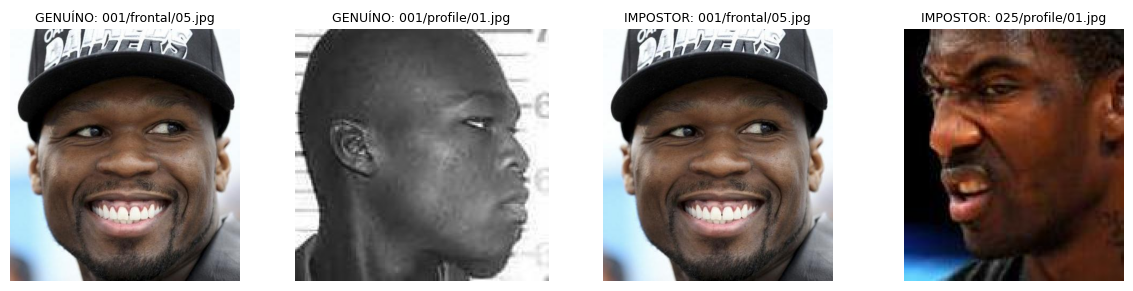

In [7]:
def read_list(path):
    """Pair_list_*.txt -> dicionário {número: 'id/frontal|profile/arquivo.jpg'}.
    Usamos uma expressão regular (regex) que procura o trecho 'ID/frontal/arquivo.jpg' na linha."""
    mapping = {}
    for n, line in enumerate(open(path, encoding="utf-8"), start=1):
        m = re.search(r"(\d+)/(frontal|profile)/([^/\s]+\.jpg)", line, re.I)
        if not m:
            continue
        first = line.split()[0] if line.split() else ""
        idx = int(first) if first.isdigit() else n      # o número da linha (ou o 1º número escrito nela)
        mapping[idx] = f"{m.group(1)}/{m.group(2).lower()}/{m.group(3)}"
    return mapping

def parse_pair_file(path):
    """same.txt / diff.txt -> lista de tuplas (número_frontal, número_perfil)."""
    pairs = []
    for line in open(path, encoding="utf-8"):
        nums = re.findall(r"\d+", line)          # pega todos os números da linha
        if len(nums) >= 2:
            pairs.append((int(nums[0]), int(nums[1])))
    return pairs

F_MAP = read_list(PAIR_LIST_F)
P_MAP = read_list(PAIR_LIST_P)
print(f"Frontais mapeadas: {len(F_MAP)} | Perfis mapeados: {len(P_MAP)}")

# Exemplo: um par genuíno e um impostor do fold 1, traduzidos e mostrados
gen = parse_pair_file(fold_dir(1) / "same.txt")[0]
imp = parse_pair_file(fold_dir(1) / "diff.txt")[0]
ex = [("GENUÍNO", gen), ("IMPOSTOR", imp)]
imgs, titles = [], []
for nome, (a, b) in ex:
    ka, kb = F_MAP[a], P_MAP[b]
    print(f"{nome}: frontal #{a} -> {ka}   |   perfil #{b} -> {kb}")
    imgs += [read_rgb(IMAGES_DIR / ka), read_rgb(IMAGES_DIR / kb)]
    titles += [f"{nome}: {ka}", f"{nome}: {kb}"]
show_images(imgs, titles, cols=4)

## 1.2 LFW

O LFW tem 13.233 imagens de 5.749 pessoas (250×250 px). Os nomes seguem o padrão `Nome/Nome_0001.jpg` (o número tem 4 dígitos, com zeros à esquerda). Usamos os arquivos de pares do conjunto de **teste** (`DevTest`): 500 genuínos + 500 impostores.

- `matchpairsDevTest.csv` (genuínos): colunas `name, imagenum1, imagenum2`: mesma pessoa, fotos 1 e 2.
- `mismatchpairsDevTest.csv` (impostores): colunas `name, imagenum1, name.1, imagenum2`: pessoa A foto 1 contra pessoa B foto 2.

> Como o LFW **só será usado para teste** (cross-dataset), a rede nunca o vê durante o treino.
>
> **Confira qual versão você baixou.** A versão *deep-funneled* (a do Kaggle citado no enunciado) já vem **alinhada**; a versão original não. Isso muda a interpretação da ablação e deve ser declarado no artigo.

Pessoas na pasta do LFW: 5749 (exemplos: ['AJ_Cook', 'AJ_Lamas', 'Aaron_Eckhart'])
CSV de genuínos  : c:\Users\gusta\Desktop\Projeto_Biometria\data\lfw\matchpairsDevTest.csv
CSV de impostores: c:\Users\gusta\Desktop\Projeto_Biometria\data\lfw\mismatchpairsDevTest.csv
Genuínos (colunas): ['name', 'imagenum1', 'imagenum2'] | 500 linhas


,name,imagenum1,imagenum2
0,Abdullah_Gul,13,14
1,Abdullah_Gul,13,16
2,Abdullatif_Sener,1,2


Impostores (colunas): ['name', 'imagenum1', 'name.1', 'imagenum2'] | 500 linhas


,name,imagenum1,name.1,imagenum2
0,AJ_Lamas,1,Zach_Safrin,1
1,Aaron_Guiel,1,Reese_Witherspoon,3
2,Aaron_Tippin,1,Jose_Luis_Rodriguez_Zapatero,1


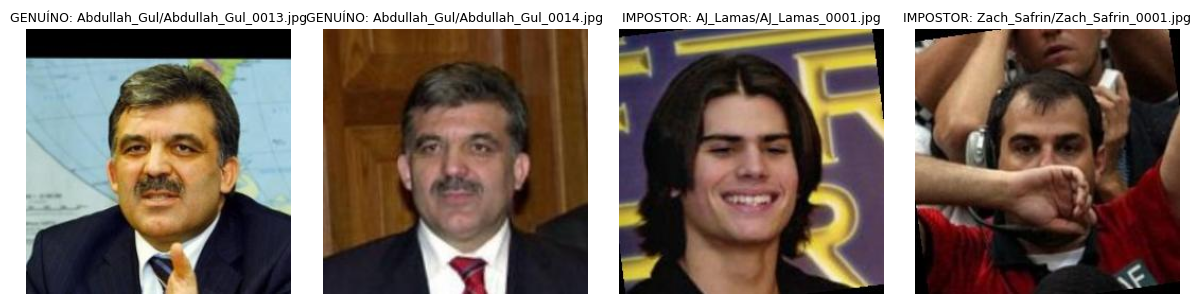

In [8]:
# Conferindo a pasta de imagens: deve conter uma subpasta por pessoa
assert LFW_RAW.exists(), f"Pasta de imagens do LFW não encontrada: {LFW_RAW}"
pessoas = sorted(p.name for p in LFW_RAW.iterdir() if p.is_dir())
print(f"Pessoas na pasta do LFW: {len(pessoas)} (exemplos: {pessoas[:3]})")

def find_csv(name):
    """Procura o CSV nos lugares mais prováveis e, se não achar, em tudo que está dentro de LFW_CSV."""
    for folder in (LFW_CSV, LFW_RAW, LFW_RAW.parent):
        if (Path(folder) / name).exists():
            return Path(folder) / name
    achados = sorted(Path(LFW_CSV).rglob(name))       # busca recursiva (pode demorar um pouco no Google Drive)
    if achados:
        return achados[0]
    raise FileNotFoundError(f"Não achei {name} dentro de {LFW_CSV}. Ele vem no mesmo download do LFW (Kaggle), junto com as imagens.")

CSV_MATCH, CSV_MISMATCH = find_csv("matchpairsDevTest.csv"), find_csv("mismatchpairsDevTest.csv")
print("CSV de genuínos  :", CSV_MATCH)
print("CSV de impostores:", CSV_MISMATCH)
match_csv    = pd.read_csv(CSV_MATCH)
mismatch_csv = pd.read_csv(CSV_MISMATCH)
print("Genuínos (colunas):", list(match_csv.columns), "|", len(match_csv), "linhas")
display(match_csv.head(3))
print("Impostores (colunas):", list(mismatch_csv.columns), "|", len(mismatch_csv), "linhas")
display(mismatch_csv.head(3))

def lfw_key(name, num):
    """('George_W_Bush', 10) -> 'George_W_Bush/George_W_Bush_0010.jpg'"""
    return f"{name}/{name}_{int(num):04d}.jpg"

r = match_csv.iloc[0]; s = mismatch_csv.iloc[0]
pair_g = (lfw_key(r.iloc[0], r.iloc[1]), lfw_key(r.iloc[0], r.iloc[2]))
pair_i = (lfw_key(s.iloc[0], s.iloc[1]), lfw_key(s.iloc[2], s.iloc[3]))
show_images([read_rgb(LFW_RAW / k) for k in pair_g + pair_i],
            ["GENUÍNO: " + pair_g[0], "GENUÍNO: " + pair_g[1], "IMPOSTOR: " + pair_i[0], "IMPOSTOR: " + pair_i[1]], cols=4)

---
# Parte 2: O protocolo experimental (a parte que mais vale nota)

Aqui decidimos **quais imagens e pares** entram em cada etapa. Um protocolo errado invalida o experimento inteiro. O plano:

| Etapa | Folds do CFP-FP | Para que serve |
|---|---|---|
| **Treino** | 1 a 6 | a rede aprende (usamos **todas** as fotos dessas pessoas: frontais e de perfil) |
| **Validação** | 7 e 8 | escolher a melhor época e **definir o threshold** |
| **Teste** | 9 e 10 | medir o resultado final (só no fim!) |

Como os 10 folds do CFP são **separados por identidade** (a própria documentação garante), cada pessoa fica em um único fold, e portanto em uma única etapa. Vamos **verificar isso no código** em vez de confiar.

### Passo 2.1: juntar todos os pares oficiais em uma tabela

In [9]:
def ident(key):
    """'001/frontal/01.jpg' -> '001' (a identidade é a 1ª parte da chave)"""
    return key.split("/")[0]

rows = []
for k in range(1, 11):                                            # os 10 folds
    for tipo, fname in (("genuine", "same.txt"), ("impostor", "diff.txt")):
        for a, b in parse_pair_file(fold_dir(k) / fname):         # (nº frontal, nº perfil)
            rows.append((F_MAP[a], P_MAP[b], tipo, k))            # traduz para chaves
ALL_PAIRS = pd.DataFrame(rows, columns=["amostra_1", "amostra_2", "tipo", "fold"])
print(ALL_PAIRS.groupby(["fold", "tipo"]).size().unstack())
display(ALL_PAIRS.head())

tipo  genuine  impostor
fold                   
1         350       350
2         350       350
3         350       350
4         350       350
5         350       350
6         350       350
7         350       350
8         350       350
9         350       350
10        350       350


,amostra_1,amostra_2,tipo,fold
0,001/frontal/05.jpg,001/profile/01.jpg,genuine,1
1,001/frontal/08.jpg,001/profile/04.jpg,genuine,1
2,001/frontal/04.jpg,001/profile/03.jpg,genuine,1
3,001/frontal/01.jpg,001/profile/02.jpg,genuine,1
4,001/frontal/09.jpg,001/profile/03.jpg,genuine,1


### Passo 2.2: verificações de sanidade (nunca pule isto)

1. Todo par **genuíno** deve ter as duas fotos da **mesma** identidade.
2. Todo par **impostor** deve ter identidades **diferentes**.
3. Nenhuma identidade pode aparecer em mais de um fold (e portanto em mais de uma etapa).

Se a (1) falhar, provavelmente a ordem frontal/perfil nos arquivos está invertida.

In [10]:
g = ALL_PAIRS[ALL_PAIRS.tipo == "genuine"]
i = ALL_PAIRS[ALL_PAIRS.tipo == "impostor"]
ruins_g = (g.amostra_1.map(ident) != g.amostra_2.map(ident)).sum()
ruins_i = (i.amostra_1.map(ident) == i.amostra_2.map(ident)).sum()
print("Genuínos com identidades diferentes (deve ser 0):", ruins_g)
print("Impostores com a mesma identidade   (deve ser 0):", ruins_i)
assert ruins_g == 0 and ruins_i == 0, "Pares inconsistentes: confira Pair_list_F/P e a ordem frontal/perfil."

# Conjunto de identidades de cada fold
fold_ids = {k: set(ALL_PAIRS[ALL_PAIRS.fold == k].amostra_1.map(ident)) | set(ALL_PAIRS[ALL_PAIRS.fold == k].amostra_2.map(ident))
            for k in range(1, 11)}
print({k: len(v) for k, v in fold_ids.items()}, "<- identidades por fold")

ids_train = set().union(*[fold_ids[k] for k in TRAIN_FOLDS])
ids_val   = set().union(*[fold_ids[k] for k in VAL_FOLDS])
ids_test  = set().union(*[fold_ids[k] for k in TEST_FOLDS])
vazamento = (ids_train & ids_val) | (ids_train & ids_test) | (ids_val & ids_test)
print("Identidades em mais de uma etapa (deve ser 0):", len(vazamento))
assert not vazamento, "VAZAMENTO de identidade entre treino/validação/teste!"

Genuínos com identidades diferentes (deve ser 0): 0
Impostores com a mesma identidade   (deve ser 0): 0
{1: 50, 2: 50, 3: 50, 4: 50, 5: 50, 6: 50, 7: 50, 8: 50, 9: 50, 10: 50} <- identidades por fold
Identidades em mais de uma etapa (deve ser 0): 0


### Passo 2.3: criar e salvar os arquivos do protocolo

Salvamos tudo em `protocols/`. Esses arquivos são o que você **combina com a outra dupla**: se os `test_pairs.csv` forem iguais nas duas duplas, a matriz 2 CNNs × 2 bases fica comparável.

| Arquivo | Conteúdo |
|---|---|
| `train.csv` | todas as fotos (frontais e perfis) das identidades de treino + a identidade de cada uma |
| `validation.csv` | pares de validação |
| `test_pairs.csv` | pares de teste |
| `genuine_pairs.csv` / `impostor_pairs.csv` | os pares separados por tipo (formato pedido no enunciado) |

In [11]:
# Todas as fotos existentes no disco, como chaves relativas
all_keys = sorted(p.relative_to(IMAGES_DIR).as_posix() for p in IMAGES_DIR.glob("*/*/*.jpg"))

# Treino = todas as fotos das identidades dos folds de treino
train_df = pd.DataFrame([(k, ident(k)) for k in all_keys if ident(k) in ids_train], columns=["key", "identity"])

val_pairs  = ALL_PAIRS[ALL_PAIRS.fold.isin(VAL_FOLDS)].reset_index(drop=True)
test_pairs = ALL_PAIRS[ALL_PAIRS.fold.isin(TEST_FOLDS)].reset_index(drop=True)

train_df.to_csv(PROTO_DIR / "train.csv", index=False)
val_pairs.to_csv(PROTO_DIR / "validation.csv", index=False)
test_pairs.to_csv(PROTO_DIR / "test_pairs.csv", index=False)
both = pd.concat([val_pairs.assign(split="validation"), test_pairs.assign(split="test")])
both[both.tipo == "genuine"].to_csv(PROTO_DIR / "genuine_pairs.csv", index=False)
both[both.tipo == "impostor"].to_csv(PROTO_DIR / "impostor_pairs.csv", index=False)

resumo = pd.DataFrame({
    "etapa": ["treino", "validação", "teste"],
    "identidades": [len(ids_train), len(ids_val), len(ids_test)],
    "imagens/pares": [f"{len(train_df)} imagens", f"{len(val_pairs)} pares", f"{len(test_pairs)} pares"],
    "genuínos": ["-", (val_pairs.tipo == "genuine").sum(), (test_pairs.tipo == "genuine").sum()],
    "impostores": ["-", (val_pairs.tipo == "impostor").sum(), (test_pairs.tipo == "impostor").sum()],
})
display(resumo)

,etapa,identidades,imagens/pares,genuínos,impostores
0,treino,300,4200 imagens,-,-
1,validação,100,1400 pares,700,700
2,teste,100,1400 pares,700,700


### Passo 2.4: protocolo do LFW (só teste)

Montamos a tabela de pares do LFW no **mesmo formato** (`amostra_1, amostra_2, tipo`) e conferimos que todas as imagens existem.

In [12]:
# itertuples(name=None) entrega cada linha como uma tupla simples: r[0], r[1], ...
rows = [(lfw_key(r[0], r[1]), lfw_key(r[0], r[2]), "genuine", "devtest") for r in match_csv.itertuples(index=False, name=None)]
rows += [(lfw_key(r[0], r[1]), lfw_key(r[2], r[3]), "impostor", "devtest") for r in mismatch_csv.itertuples(index=False, name=None)]
lfw_pairs = pd.DataFrame(rows, columns=["amostra_1", "amostra_2", "tipo", "fold"])

faltando = [k for k in set(lfw_pairs.amostra_1) | set(lfw_pairs.amostra_2) if not (LFW_RAW / k).exists()]
assert not faltando, f"{len(faltando)} imagens do LFW não encontradas em {LFW_RAW}. Exemplos: {faltando[:3]}"

lfw_pairs.to_csv(PROTO_DIR / "lfw_test_pairs.csv", index=False)
print(lfw_pairs.tipo.value_counts().to_dict(), "| imagens únicas:", len(set(lfw_pairs.amostra_1) | set(lfw_pairs.amostra_2)))

{'genuine': 500, 'impostor': 500} | imagens únicas: 1549


---
# Parte 3: Pré-processamento (detectar → alinhar → recortar)

Uma CNN funciona melhor quando todos os rostos chegam **no mesmo lugar e na mesma posição**: olhos na mesma altura, nariz no centro. O pipeline mínimo do enunciado para face é:

1. **Detecção:** achar o rosto na foto (usamos o detector **YuNet**, que devolve a caixa do rosto e **5 pontos**: olho direito, olho esquerdo, nariz e dois cantos da boca);
2. **Alinhamento:** girar/escalar/transladar a imagem para que esses 5 pontos caiam em posições fixas de um **template** (o do ArcFace, para imagens 112×112);
3. **Recorte:** ficar só com a região do rosto, em 112×112;
4. **Normalização:** feita mais adiante, ao transformar em tensor (Parte 4).

**FTA (*Failure to Acquire*):** se o detector não achar rosto (comum em fotos de **perfil**), usamos um recorte central como plano B **e contamos a falha**. O enunciado pede essa métrica.

### Passo 3.1: carregar o detector

In [13]:
# Template do ArcFace: posição ideal (em 112x112) de: olho esq., olho dir., nariz, canto esq. da boca, canto dir. da boca
TEMPLATE = np.array([[38.2946, 51.6963], [73.5318, 51.5014], [56.0252, 71.7366],
                     [41.5493, 92.3655], [70.7299, 92.2041]], dtype=np.float32)

def get_detector():
    """Baixa (uma vez) e carrega o detector YuNet. Devolve None se não conseguir."""
    if not YUNET_PATH.exists():
        try:
            print("Baixando o detector YuNet...")
            urllib.request.urlretrieve(YUNET_URL, str(YUNET_PATH))
        except Exception as e:
            if YUNET_PATH.exists(): YUNET_PATH.unlink()
            print("Não consegui baixar o detector:", e)
            return None
    return cv2.FaceDetectorYN.create(str(YUNET_PATH), "", (320, 320), DETECT_SCORE)

DETECTOR = get_detector()
if DETECTOR is None and REQUIRE_DETECTOR:
    raise RuntimeError(
        "Detector de rosto indisponível. Baixe manualmente o arquivo\n"
        f"  {YUNET_URL}\ne coloque em:\n  {YUNET_PATH}\ndepois rode esta célula de novo.")
print("Detector pronto:", DETECTOR is not None)

Detector pronto: True


### Passo 3.2: as funções de detecção, alinhamento e recorte

**Alinhamento por similaridade.** `cv2.estimateAffinePartial2D` calcula a melhor combinação de **rotação + escala + translação** que leva os 5 pontos detectados o mais perto possível dos 5 pontos do template. `cv2.warpAffine` aplica essa transformação na imagem inteira, já cortando em 112×112.

In [14]:
def center_crop_resize(img_bgr, size):
    """Plano B: recorta o maior quadrado central e redimensiona."""
    h, w = img_bgr.shape[:2]
    s = min(h, w)
    y, x = (h - s) // 2, (w - s) // 2
    return cv2.resize(img_bgr[y:y + s, x:x + s], (size, size), interpolation=cv2.INTER_AREA)

def align_by_landmarks(img_bgr, landmarks, size):
    """Leva os 5 pontos detectados para as posições do template (rotaciona, escala, translada)."""
    dst = TEMPLATE * (size / 112.0)
    M, _ = cv2.estimateAffinePartial2D(landmarks.astype(np.float32), dst, method=cv2.LMEDS)
    if M is None:
        return None
    return cv2.warpAffine(img_bgr, M, (size, size), flags=cv2.INTER_LINEAR)

def detect_face(img_bgr, detector):
    """Devolve (caixa, 5 landmarks) do MAIOR rosto, ou None se nada foi detectado."""
    h, w = img_bgr.shape[:2]
    detector.setInputSize((w, h))
    _, faces = detector.detect(img_bgr)
    if faces is None or len(faces) == 0:
        return None
    f = faces[np.argmax(faces[:, 2] * faces[:, 3])]      # escolhe o rosto de maior área (largura x altura)
    return f[:4], f[4:14].reshape(5, 2)                  # [x, y, w, h] e 5 pontos (x, y)

def align_face(img_bgr, detector, size):
    """Pipeline completo. None = falha de detecção (FTA)."""
    det = detect_face(img_bgr, detector)
    if det is None:
        return None
    return align_by_landmarks(img_bgr, det[1], size)

### Passo 3.3: ver o pré-processamento em ação (guarde essa figura para o artigo!)

O artigo e a apresentação **exigem exemplos visuais de cada etapa**. A célula abaixo mostra, para uma foto frontal e uma de perfil: original → detecção (caixa + 5 pontos) → rosto alinhado. A figura é salva em `results/preprocess_examples.png`.

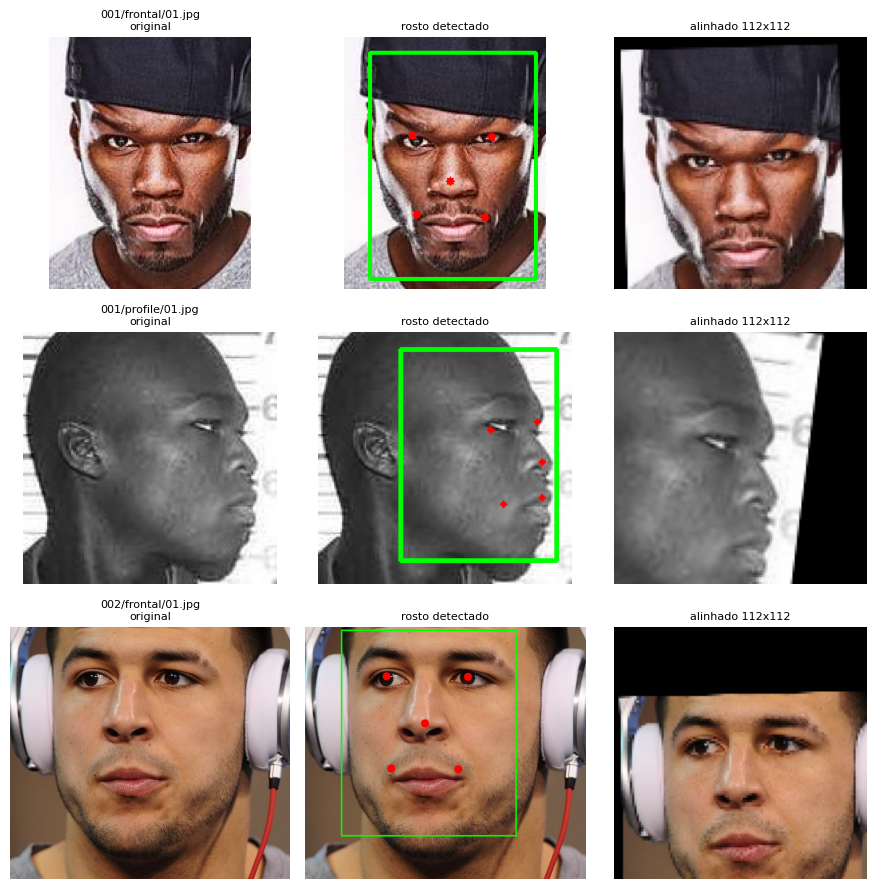

In [15]:
def preprocess_demo(keys, root, detector, size=IMAGE_SIZE):
    fig, axes = plt.subplots(len(keys), 3, figsize=(9, 3 * len(keys)))
    axes = np.atleast_2d(axes)
    for r, key in enumerate(keys):
        bgr = cv2.imread(str(Path(root) / key))
        det = detect_face(bgr, detector) if detector is not None else None
        vis = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).copy()
        if det is not None:
            (x, y, w, h), lmk = det
            cv2.rectangle(vis, (int(x), int(y)), (int(x + w), int(y + h)), (0, 255, 0), 2)     # caixa verde
            for px, py in lmk:
                cv2.circle(vis, (int(px), int(py)), max(2, vis.shape[0] // 60), (255, 0, 0), -1)   # pontos vermelhos
            aligned = cv2.cvtColor(align_by_landmarks(bgr, lmk, size), cv2.COLOR_BGR2RGB)
            status = "rosto detectado"
        else:
            aligned = cv2.cvtColor(center_crop_resize(bgr, size), cv2.COLOR_BGR2RGB)
            status = "FALHA na detecção (recorte central)"
        for ax, im, t in zip(axes[r], [cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), vis, aligned],
                             ["original", status, f"alinhado {size}x{size}"]):
            ax.imshow(im); ax.set_title(f"{key}\n{t}" if t == "original" else t, fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.savefig(RES_DIR / "preprocess_examples.png", dpi=150); plt.show()

demo_keys = [f"{identities[0]}/frontal/01.jpg", f"{identities[0]}/profile/01.jpg", f"{identities[1]}/frontal/01.jpg"]
preprocess_demo(demo_keys, IMAGES_DIR, DETECTOR)

### Passo 3.4: processar **todas** as imagens e salvar

Rodamos o pipeline em todas as fotos do CFP e nas fotos do LFW usadas nos pares. Cada imagem processada é salva como **PNG** (sem perda de qualidade) em `processed/`, espelhando a estrutura de pastas original. Assim o pré-processamento (que é lento) roda **uma única vez**; o treino e a avaliação só leem os PNGs prontos.

Também guardamos um `preprocess_log.csv` dizendo, para cada imagem, se o detector funcionou. É dele que sai o **FTA**.

> No Colab com GPU, o CFP inteiro (7.000 imagens) leva alguns minutos. Se o log já existir, a célula **pula** o trabalho.

In [16]:
def processed_file(root, key):
    """Chave 'id/frontal/01.jpg' -> <root>/id/frontal/01.png"""
    return Path(root) / Path(key).with_suffix(".png")

def process_keys(keys, src_root, out_root, size, detector):
    """Processa cada imagem e grava <out_root>/<chave>.png.
    detector=None -> só recorte central (usado na ablação)."""
    out_root = Path(out_root); out_root.mkdir(parents=True, exist_ok=True)
    log_path = out_root / "preprocess_log.csv"
    if log_path.exists():
        print(f"  (já processado: {out_root.name}; apague {log_path.name} para refazer)")
        return pd.read_csv(log_path)
    rows = []
    for key in tqdm(keys, desc=f"processando -> {out_root.name}"):
        bgr = cv2.imread(str(Path(src_root) / key))
        if bgr is None:
            raise FileNotFoundError(f"Não consegui ler {Path(src_root) / key}")
        out = align_face(bgr, detector, size) if detector is not None else None
        detected = out is not None
        if out is None:
            out = center_crop_resize(bgr, size)               # plano B
        dst = processed_file(out_root, key)
        dst.parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(dst), out)
        rows.append((key, detected if detector is not None else True))
    log = pd.DataFrame(rows, columns=["key", "detected"])
    log.to_csv(log_path, index=False)
    return log

lfw_keys = sorted(set(lfw_pairs.amostra_1) | set(lfw_pairs.amostra_2))
log_cfp = process_keys(all_keys, IMAGES_DIR, CFP_PROC, IMAGE_SIZE, DETECTOR)
log_lfw = process_keys(lfw_keys, LFW_RAW, LFW_PROC, IMAGE_SIZE, DETECTOR)

if DETECTOR is not None:
    for nome, lg in (("CFP", log_cfp), ("LFW", log_lfw)):
        print(f"{nome}: detecção bem-sucedida em {lg.detected.mean() * 100:.1f}% das imagens ({(~lg.detected).sum()} falhas)")
    # FTA do CFP separado por tipo (perfil costuma falhar mais)
    lg = log_cfp.assign(tipo=log_cfp.key.str.split("/").str[1])
    print("FTA do CFP por tipo de foto:\n", (1 - lg.groupby("tipo").detected.mean()).round(3).to_dict())

  (já processado: cfp_fp; apague preprocess_log.csv para refazer)
  (já processado: lfw; apague preprocess_log.csv para refazer)
CFP: detecção bem-sucedida em 99.5% das imagens (34 falhas)
LFW: detecção bem-sucedida em 100.0% das imagens (0 falhas)
FTA do CFP por tipo de foto:
 {'frontal': 0.001, 'profile': 0.015}


---
# Parte 4: Dataset e DataLoader (como as imagens entram na rede)

A rede não lê arquivos `.png`: ela recebe **tensores** (matrizes de números). A cadeia é:

```
arquivo PNG -> imagem PIL -> [augmentation] -> ToTensor -> Normalize -> tensor (3, 112, 112)
```

- **`ToTensor`**: converte para tensor e muda a escala de 0..255 para **0..1**; também reordena de (altura, largura, canais) para **(canais, altura, largura)**, que é o formato do PyTorch.
- **`Normalize(média, desvio)`**: subtrai a média e divide pelo desvio de cada canal. Usamos os valores da **ImageNet**, porque a ResNet50 foi pré-treinada com essa normalização.
- **Data augmentation (só no treino):** pequenas alterações aleatórias (espelhar, mudar brilho/contraste, girar até 10°). Cada época a rede vê versões ligeiramente diferentes das mesmas fotos, o que ajuda a **não decorar** as imagens (overfitting). Na validação e no teste **não** se faz augmentation.
- **`Dataset`**: sabe entregar a imagem número *i* e seu rótulo.
- **`DataLoader`**: agrupa várias imagens em **lotes (batches)** e embaralha no treino.

In [17]:
train_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),                  # espelha 50% das vezes
    transforms.ColorJitter(0.2, 0.2, 0.2),              # brilho, contraste, saturação
    transforms.RandomRotation(10),                      # gira até +-10 graus
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([                          # avaliação: SEM augmentation
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class ImageDataset(Dataset):
    """Entrega (tensor_da_imagem, rótulo). `perturb` permite degradar a imagem (usado na robustez)."""
    def __init__(self, root, keys, labels=None, transform=None, perturb=None):
        self.root, self.keys, self.labels = root, list(keys), labels
        self.transform, self.perturb = transform, perturb
    def __len__(self):
        return len(self.keys)
    def __getitem__(self, i):
        img = Image.open(processed_file(self.root, self.keys[i])).convert("RGB")   # lê o PNG processado
        if self.perturb is not None:
            img = self.perturb(img)
        if self.transform is not None:
            img = self.transform(img)
        return img, (i if self.labels is None else self.labels[i])   # sem rótulo: devolve o índice

# Rótulos do treino: cada identidade vira um número de 0 a (N-1)
classes = sorted(train_df.identity.unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
train_labels = [class_to_idx[c] for c in train_df.identity]
print(f"{len(classes)} classes (identidades) no treino | {len(train_df)} imagens")

g = torch.Generator(); g.manual_seed(SEED)           # controla a ordem do embaralhamento
train_ds = ImageDataset(CFP_PROC, train_df.key.tolist(), train_labels, train_tf)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=g)

x, y = next(iter(train_dl))
print("Um lote -> imagens:", tuple(x.shape), "(lote, canais, altura, largura) | rótulos:", tuple(y.shape))
print(f"Valores dos pixels depois de normalizar: min={x.min():.2f}  max={x.max():.2f}  (não é mais 0..255)")

300 classes (identidades) no treino | 4200 imagens
Um lote -> imagens: (32, 3, 112, 112) (lote, canais, altura, largura) | rótulos: (32,)
Valores dos pixels depois de normalizar: min=-2.12  max=2.64  (não é mais 0..255)


Veja o **data augmentation** funcionando: a mesma foto, passada 8 vezes pelo pipeline de treino. (Para exibir, desfazemos a normalização.)

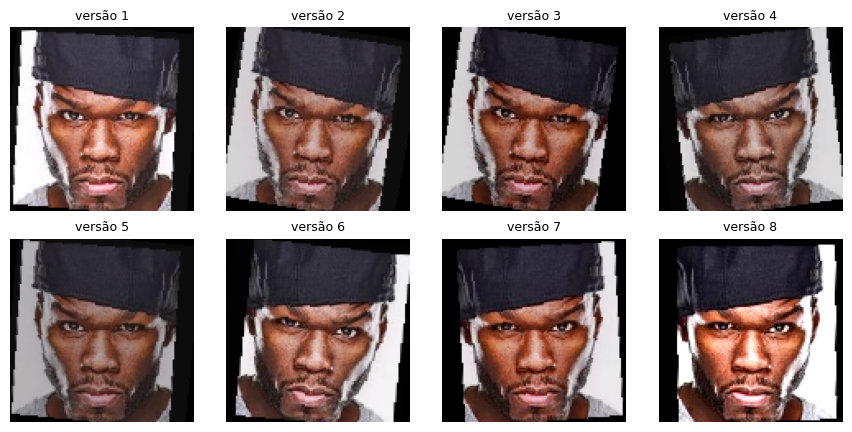

In [18]:
def denormalize(t):
    """Desfaz a normalização para poder mostrar o tensor como imagem."""
    m = torch.tensor(MEAN).view(3, 1, 1); s = torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

one = Image.open(processed_file(CFP_PROC, train_df.key.iloc[0])).convert("RGB")
show_images([denormalize(train_tf(one)) for _ in range(8)], [f"versão {i + 1}" for i in range(8)], cols=4, size=2.2)

---
# Parte 5: O modelo (ResNet50 + embedding + ArcFace)

### 5.1 A arquitetura

```
imagem 3x112x112
   |
ResNet50 (sem a última camada de classificação)  ->  vetor de 2048 números
   |
Dropout(0.4) -> Linear(2048 -> 512) -> BatchNorm  ->  EMBEDDING (512 números)
   |
(só no treino) camada ArcFace  ->  "qual das N pessoas é?"
```

- **ResNet50:** rede com 50 camadas, **pré-treinada na ImageNet** (1,2 milhão de fotos de objetos). Ela já sabe detectar bordas, texturas e formas. Estamos reaproveitando esse conhecimento (**transfer learning**) em vez de começar do zero.
- **Cabeça de embedding:** como a saída original (2048) é grande, uma camada `Linear` comprime para 512, e o `BatchNorm` estabiliza o treino.
- **Congelar camadas:** `conv1`, `layer1` e `layer2` (as primeiras, que detectam padrões simples) **não são treinadas**. Treinamos só `layer3`, `layer4` e a cabeça. Isso é mais rápido e funciona melhor com poucos dados.

In [19]:
class FaceEmbeddingNet(nn.Module):
    def __init__(self, embedding_dim=EMBEDDING_DIM, dropout=DROPOUT, pretrained=PRETRAINED, freeze_layers=FREEZE_LAYERS):
        super().__init__()
        weights = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = models.resnet50(weights=weights)       # baixa os pesos da ImageNet na primeira vez
        feat = backbone.fc.in_features                    # 2048
        backbone.fc = nn.Identity()                       # remove o classificador original de 1000 classes
        self.backbone = backbone
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(feat, embedding_dim), nn.BatchNorm1d(embedding_dim))
        self.freeze_layers = list(freeze_layers)
        for name in self.freeze_layers:                   # congela: requires_grad=False = "não treine isto"
            for p in getattr(self.backbone, name).parameters():
                p.requires_grad = False

    def train(self, mode=True):
        super().train(mode)
        for name in self.freeze_layers:                   # camadas congeladas também mantêm o BatchNorm fixo
            getattr(self.backbone, name).eval()
        return self

    def forward(self, x):
        return self.head(self.backbone(x))                # devolve o embedding (ainda sem normalizar)

model = FaceEmbeddingNet().to(DEVICE)
total = sum(p.numel() for p in model.parameters())
treinavel = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parâmetros totais: {total:,} | treináveis: {treinavel:,} | congelados: {total - treinavel:,}")
print("Saída para um lote de 4 imagens:", tuple(model.eval()(torch.randn(4, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)).shape))

Parâmetros totais: 24,558,144 | treináveis: 23,113,216 | congelados: 1,444,928
Saída para um lote de 4 imagens: (4, 512)


### 5.2 O ArcFace (a loss que molda os embeddings)

Em uma classificação comum, a rede calcula, para cada pessoa do treino, uma pontuação (*logit*). O ArcFace trabalha com **ângulos**:

1. normaliza o embedding e os pesos de cada classe (ficam com comprimento 1);
2. o **cosseno** entre eles mede o quão perto o rosto está do "centro" de cada pessoa;
3. para a **classe correta**, soma-se uma **margem angular** $m$ ao ângulo: $\cos(\theta + m)$ no lugar de $\cos\theta$;
4. multiplica-se tudo por uma escala $s$ e aplica-se a entropia cruzada.

**Por quê?** A margem deixa a tarefa propositalmente **mais difícil**: para acertar, o rosto precisa ficar *bem* perto do centro da própria pessoa, com folga. O resultado são grupos compactos (mesma pessoa) e bem separados (pessoas diferentes). Exatamente o que a verificação precisa.

Um exemplo numérico para fixar a ideia:

In [20]:
cos_theta = 0.80                         # rosto bem alinhado com a sua própria classe
theta = math.acos(cos_theta)
com_margem = math.cos(theta + ARC_MARGIN)
print(f"ângulo = {math.degrees(theta):.1f} graus")
print(f"cosseno SEM margem: {cos_theta:.3f}  |  COM margem m={ARC_MARGIN}: {com_margem:.3f}")
print(f"logits (x escala {ARC_SCALE:.0f}): {cos_theta * ARC_SCALE:.1f} -> {com_margem * ARC_SCALE:.1f}")
print("-> com a margem a pontuação da classe correta CAI, e a rede é forçada a aproximar mais o rosto do seu centro para compensar.")

ângulo = 36.9 graus
cosseno SEM margem: 0.800  |  COM margem m=0.5: 0.414
logits (x escala 30): 24.0 -> 12.4
-> com a margem a pontuação da classe correta CAI, e a rede é forçada a aproximar mais o rosto do seu centro para compensar.


In [21]:
class ArcMarginProduct(nn.Module):
    """Camada ArcFace (Deng et al., CVPR 2019). Só existe no treino."""
    def __init__(self, in_features, num_classes, s=ARC_SCALE, m=ARC_MARGIN):
        super().__init__()
        self.s, self.m = s, m
        self.weight = nn.Parameter(torch.empty(num_classes, in_features))   # um "centro" por pessoa
        nn.init.xavier_uniform_(self.weight)
        self.cos_m, self.sin_m = math.cos(m), math.sin(m)
        self.th = math.cos(math.pi - m)          # limite para evitar que theta+m passe de 180 graus
        self.mm = math.sin(math.pi - m) * m

    def forward(self, emb, labels):
        cosine = F.linear(F.normalize(emb), F.normalize(self.weight))          # cos(theta) com cada classe
        sine = torch.sqrt((1.0 - cosine ** 2).clamp(0, 1))
        phi = cosine * self.cos_m - sine * self.sin_m                          # cos(theta + m)
        phi = torch.where(cosine > self.th, phi, cosine - self.mm)             # trata o caso extremo
        one_hot = F.one_hot(labels, cosine.size(1)).float()                    # 1 só na classe correta
        return self.s * (one_hot * phi + (1.0 - one_hot) * cosine)             # margem só na classe correta

arc = ArcMarginProduct(EMBEDDING_DIM, len(classes)).to(DEVICE)
print("Camada ArcFace criada para", len(classes), "classes.")

Camada ArcFace criada para 300 classes.


---
# Parte 6: Embeddings, cosseno, threshold e métricas

Antes de treinar, precisamos das **ferramentas de medição**, porque o treino as usa na validação.

### 6.1 Extrair embeddings e calcular os scores
Para cada par, o **score** é a similaridade de cosseno entre os dois embeddings. Como os embeddings ficam **normalizados (norma 1)**, o cosseno é simplesmente o **produto escalar** entre eles. O resultado vai de −1 a 1; quanto maior, mais parecidos.

Extraímos o embedding de cada imagem **uma vez só** (um dicionário `chave -> linha da matriz`) e depois montamos os scores dos pares por indexação.

In [22]:
@torch.no_grad()      # não calcula gradientes (economiza memória e tempo; só estamos medindo)
def extract_embeddings(model, root, keys, perturb=None, batch_size=64):
    """Devolve uma matriz (n_imagens, 512) com os embeddings L2-normalizados, na ordem de `keys`."""
    ds = ImageDataset(root, keys, None, eval_tf, perturb)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)
    model.eval()                                       # modo avaliação: desliga dropout e fixa o BatchNorm
    out = np.zeros((len(keys), EMBEDDING_DIM), dtype=np.float32)
    for x, idx in dl:
        e = F.normalize(model(x.to(DEVICE)), dim=1)    # normalização L2: comprimento do vetor = 1
        out[idx.numpy()] = e.cpu().numpy()
    return out

def score_pairs(emb, keys, pairs):
    """Cosseno de cada par. Devolve (scores, labels) com label 1 = genuíno, 0 = impostor."""
    index = {k: i for i, k in enumerate(keys)}
    a = np.array([index[k] for k in pairs.amostra_1])
    b = np.array([index[k] for k in pairs.amostra_2])
    scores = np.sum(emb[a] * emb[b], axis=1)           # produto escalar = cosseno (vetores com norma 1)
    labels = (pairs.tipo.values == "genuine").astype(int)
    return scores, labels

def embed_pairs(model, root, pairs, perturb=None):
    keys = sorted(set(pairs.amostra_1) | set(pairs.amostra_2))      # imagens únicas dos pares
    emb = extract_embeddings(model, root, keys, perturb)
    scores, labels = score_pairs(emb, keys, pairs)
    return scores, labels, keys

### 6.2 Threshold, FMR, FNMR e EER (com um exemplo de brinquedo)

Dado um threshold $t$, a decisão é: **score ≥ t → "mesma pessoa"**. Dois tipos de erro:

| Erro | Nome | O que significa | Fórmula |
|---|---|---|---|
| Aceitar um impostor | **FMR** (False Match Rate) | par impostor com score ≥ t | impostores aceitos / total de impostores |
| Rejeitar um genuíno | **FNMR** (False Non-Match Rate) | par genuíno com score < t | genuínos rejeitados / total de genuínos |

Existe um **trade-off**: subir o threshold reduz o FMR (mais seguro) mas aumenta o FNMR (mais incômodo para o usuário legítimo). O **EER** (Equal Error Rate) é o ponto em que **FMR = FNMR**: um número único e sem threshold fixo para comparar sistemas (quanto menor, melhor). A **curva ROC** mostra todos os pontos de operação possíveis, e a **AUC** é a área sob ela (1,0 = perfeito, 0,5 = chute).

Vamos ver isso com scores **inventados**, onde sabemos a resposta:

EER = 0.044 no threshold 0.351

threshold |  FMR  | FNMR
  0.100   | 0.468 | 0.000
  0.200   | 0.222 | 0.004
  0.351   | 0.044 | 0.044   <- EER
  0.500   | 0.002 | 0.266
  0.600   | 0.000 | 0.516


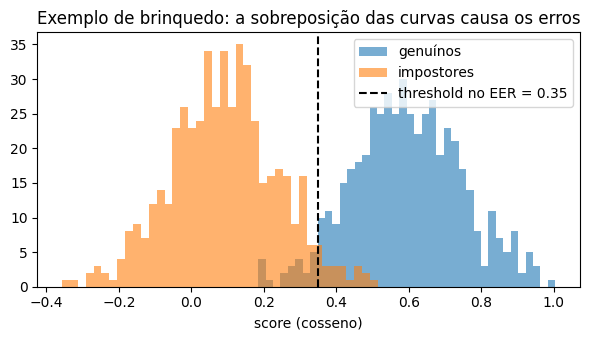

In [23]:
def compute_eer(labels, scores):
    """Devolve (EER, threshold no ponto do EER)."""
    fpr, tpr, thr = roc_curve(labels, scores)    # fpr = FMR; tpr = 1 - FNMR
    fnr = 1 - tpr
    i = int(np.nanargmin(np.abs(fnr - fpr)))     # ponto onde FMR e FNMR são mais próximos
    return float((fpr[i] + fnr[i]) / 2), float(thr[i])

def metrics_at(labels, scores, thr):
    """FMR, FNMR e acurácia para um threshold fixo."""
    gen, imp = scores[labels == 1], scores[labels == 0]
    fmr  = float(np.mean(imp >= thr))            # impostores aceitos
    fnmr = float(np.mean(gen < thr))             # genuínos rejeitados
    acc  = float((np.sum(gen >= thr) + np.sum(imp < thr)) / len(scores))
    return fmr, fnmr, acc

# --- Exemplo de brinquedo: genuínos com score médio 0.6, impostores com média 0.1
rng = np.random.RandomState(0)
toy_scores = np.concatenate([rng.normal(0.6, 0.15, 500), rng.normal(0.1, 0.15, 500)])
toy_labels = np.concatenate([np.ones(500), np.zeros(500)]).astype(int)
toy_eer, toy_thr = compute_eer(toy_labels, toy_scores)
print(f"EER = {toy_eer:.3f} no threshold {toy_thr:.3f}\n")
print("threshold |  FMR  | FNMR")
for t in [0.1, 0.2, toy_thr, 0.5, 0.6]:
    fmr, fnmr, _ = metrics_at(toy_labels, toy_scores, t)
    print(f"  {t:.3f}   | {fmr:.3f} | {fnmr:.3f}" + ("   <- EER" if t == toy_thr else ""))

plt.figure(figsize=(6, 3.5))
plt.hist(toy_scores[toy_labels == 1], bins=40, alpha=.6, label="genuínos"); plt.hist(toy_scores[toy_labels == 0], bins=40, alpha=.6, label="impostores")
plt.axvline(toy_thr, color="k", ls="--", label=f"threshold no EER = {toy_thr:.2f}")
plt.xlabel("score (cosseno)"); plt.legend(); plt.title("Exemplo de brinquedo: a sobreposição das curvas causa os erros"); plt.tight_layout(); plt.show()

In [24]:
def full_metrics(labels, scores, thr):
    """Todas as métricas pedidas no enunciado para um threshold dado."""
    fpr, tpr, _ = roc_curve(labels, scores)
    eer, _ = compute_eer(labels, scores)
    fmr, fnmr, acc = metrics_at(labels, scores, thr)
    return {"eer": eer,
            "auc": float(roc_auc_score(labels, scores)),
            "fmr": fmr, "fnmr": fnmr,
            "tar_at_far_1pct": float(np.interp(0.01, fpr, tpr)),   # TAR (=1-FNMR) quando FAR = 1%
            "accuracy_at_threshold": acc, "threshold": float(thr),
            "n_genuine": int((labels == 1).sum()), "n_impostor": int((labels == 0).sum())}

def fta_rate(root, keys):
    """FTA: fração das imagens em que o detector falhou (lido do preprocess_log.csv)."""
    log = Path(root) / "preprocess_log.csv"
    if not log.exists():
        return None
    df = pd.read_csv(log).set_index("key").reindex(keys)
    return float((~df.detected.fillna(True).astype(bool)).mean())

def save_scores(path, pairs, scores):
    """Formato pedido no enunciado: amostra_1, amostra_2, tipo, score."""
    pd.DataFrame({"amostra_1": pairs.amostra_1.values, "amostra_2": pairs.amostra_2.values,
                  "tipo": pairs.tipo.values, "score": np.round(scores, 6)}).to_csv(path, index=False)

def plot_roc(labels, scores, path, title="Curva ROC"):
    fpr, tpr, _ = roc_curve(labels, scores)
    plt.figure(figsize=(4.5, 4.5))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(labels, scores):.4f}"); plt.plot([0, 1], [0, 1], "k--", lw=.8)
    plt.xlabel("FMR (FAR)"); plt.ylabel("TAR (1 - FNMR)"); plt.title(title); plt.legend(); plt.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

def plot_distributions(labels, scores, thr, path, title="Distribuição dos scores"):
    plt.figure(figsize=(6, 3.8))
    plt.hist(scores[labels == 1], bins=40, alpha=.6, density=True, label="Genuínos")
    plt.hist(scores[labels == 0], bins=40, alpha=.6, density=True, label="Impostores")
    plt.axvline(thr, color="k", ls="--", label=f"Threshold = {thr:.3f}")
    plt.xlabel("Similaridade de cosseno"); plt.ylabel("Densidade"); plt.title(title); plt.legend()
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

---
# Parte 7: Treino (fine-tuning)

**O que acontece em cada passo:**

1. pega um lote de imagens (com seus rótulos de identidade);
2. a rede gera os embeddings;
3. o ArcFace calcula os logits e a loss (entropia cruzada);
4. `loss.backward()` calcula o quanto cada peso contribuiu para o erro (gradientes);
5. `opt.step()` ajusta os pesos na direção que reduz a loss.

**Ao fim de cada época** (uma passada por todas as imagens de treino) medimos o **EER na validação**. Guardamos o checkpoint com o **menor EER de validação** (o melhor modelo) e paramos mais cedo (*early stopping*) se não houver melhora por `PATIENCE` épocas. O **teste não é tocado aqui.**

**Detalhes de otimização:**
- **Adam:** otimizador que adapta o passo de cada peso.
- **Learning rate diferente:** o backbone (já bom) usa `1e-4`; a cabeça e o ArcFace (novos, aleatórios) usam 10× mais.
- **Cosine annealing:** o learning rate decai suavemente ao longo das épocas.

> Dica: com GPU do Colab, cada época leva poucos minutos. Se a sessão cair, o checkpoint fica no seu Drive e a célula **pula o treino** na próxima vez (a menos que `RETRAIN = True`).

época 01 | loss 19.8013 | EER validação 0.2557 | 49s


época 02 | loss 17.6155 | EER validação 0.2136 | 21s


época 03 | loss 15.7106 | EER validação 0.2079 | 20s


época 04 | loss 13.4423 | EER validação 0.2071 | 20s


época 05 | loss 11.2200 | EER validação 0.2071 | 20s


época 06 | loss 8.8900 | EER validação 0.1986 | 20s


época 07 | loss 6.8262 | EER validação 0.2293 | 20s


época 08 | loss 5.1435 | EER validação 0.2093 | 20s


época 09 | loss 3.6903 | EER validação 0.2186 | 20s


época 10 | loss 2.6843 | EER validação 0.2343 | 20s
Early stopping.

Melhor EER de validação: 0.1986  -> c:\Users\gusta\Desktop\Projeto_Biometria\saidas\checkpoints\best_seed42.pt


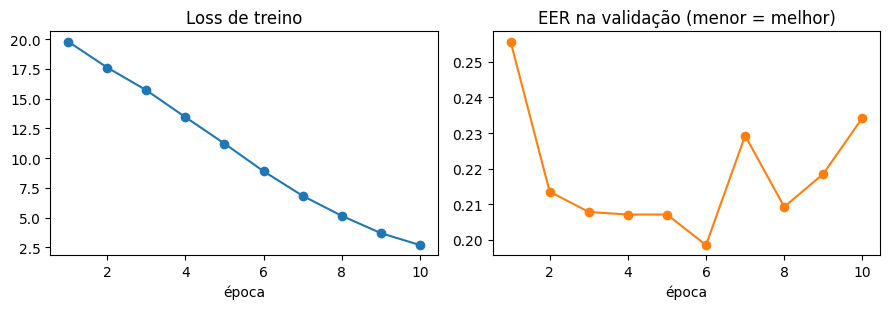

In [25]:
CKPT_PATH = CKPT_DIR / f"best_seed{SEED}.pt"

if CKPT_PATH.exists() and not RETRAIN:
    print("Checkpoint encontrado, pulando o treino:", CKPT_PATH)
    history = pd.read_csv(RES_DIR / f"train_log_seed{SEED}.csv") if (RES_DIR / f"train_log_seed{SEED}.csv").exists() else None
else:
    set_seed(SEED)
    model = FaceEmbeddingNet().to(DEVICE)
    arc = ArcMarginProduct(EMBEDDING_DIM, len(classes)).to(DEVICE)
    opt = torch.optim.Adam(
        [{"params": [p for p in model.backbone.parameters() if p.requires_grad], "lr": LEARNING_RATE},
         {"params": list(model.head.parameters()) + list(arc.parameters()), "lr": LEARNING_RATE * HEAD_LR_MULT}],
        weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    criterion = nn.CrossEntropyLoss()

    best_eer, bad_epochs, log = 1.0, 0, []
    for epoch in range(1, EPOCHS + 1):
        model.train(); arc.train()                    # modo treino: dropout ligado, BatchNorm atualiza
        t0, total_loss, n = time.time(), 0.0, 0
        for x, y in tqdm(train_dl, desc=f"época {epoch}/{EPOCHS}", leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = criterion(arc(model(x), y), y)     # embedding -> ArcFace -> loss
            opt.zero_grad()                           # zera os gradientes da iteração anterior
            loss.backward()                           # calcula os gradientes
            opt.step()                                # atualiza os pesos
            total_loss += loss.item() * len(y); n += len(y)
        sched.step()

        # --- validação: EER nos pares de validação (a rede NÃO treina com isto)
        v_scores, v_labels, _ = embed_pairs(model, CFP_PROC, val_pairs)
        val_eer, _ = compute_eer(v_labels, v_scores)
        log.append({"epoch": epoch, "train_loss": total_loss / n, "val_eer": val_eer, "sec": time.time() - t0})
        print(f"época {epoch:02d} | loss {total_loss / n:.4f} | EER validação {val_eer:.4f} | {time.time() - t0:.0f}s")

        if val_eer < best_eer:                        # melhorou: guarda este modelo
            best_eer, bad_epochs = val_eer, 0
            torch.save({"model": model.state_dict(), "seed": SEED, "epoch": epoch, "val_eer": val_eer}, CKPT_PATH)
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print("Early stopping."); break
        pd.DataFrame(log).to_csv(RES_DIR / f"train_log_seed{SEED}.csv", index=False)
    history = pd.DataFrame(log)
    print(f"\nMelhor EER de validação: {best_eer:.4f}  -> {CKPT_PATH}")

if history is not None:
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
    ax[0].plot(history.epoch, history.train_loss, marker="o"); ax[0].set_title("Loss de treino"); ax[0].set_xlabel("época")
    ax[1].plot(history.epoch, history.val_eer, marker="o", color="C1"); ax[1].set_title("EER na validação (menor = melhor)"); ax[1].set_xlabel("época")
    plt.tight_layout(); plt.savefig(RES_DIR / "training_curves.png", dpi=150); plt.show()

---
# Parte 8: Avaliação no teste do CFP-FP

Agora, o momento da verdade, e com **a ordem certa**:

1. carregamos o **melhor** modelo (do checkpoint);
2. calculamos os scores dos pares de **validação**;
3. escolhemos o **threshold** no ponto do EER **da validação**;
4. **congelamos** o threshold (salvo em `threshold.json`);
5. só então calculamos os scores do **teste** e aplicamos esse threshold fixo.

Se escolhêssemos o threshold olhando o teste, o resultado ficaria otimista e injusto (é um dos erros eliminatórios do enunciado).

Modelo carregado (época 6, EER de validação 0.1986)
Threshold escolhido na validação: 0.1363 (EER de validação = 0.1986)  -> CONGELADO


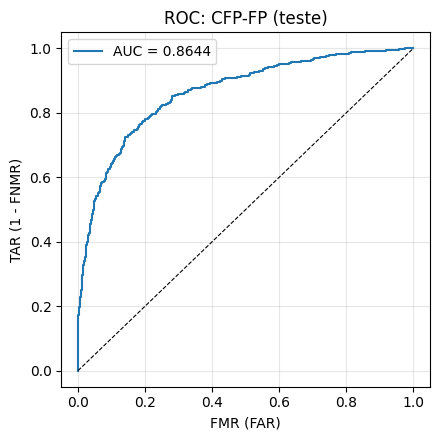

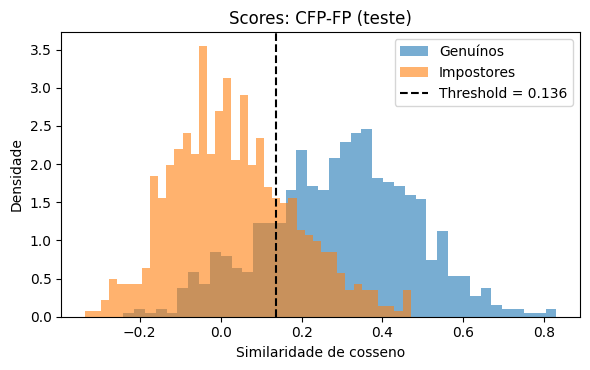

,CFP-FP (teste)
eer,0.2129
auc,0.8644
fmr,0.2371
fnmr,0.1957
tar_at_far_1pct,0.2500
accuracy_at_threshold,0.7836
threshold,0.1363
n_genuine,700.0000
n_impostor,700.0000


FTA: 0.0033927056827820186


In [26]:
def load_best_model():
    ck = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=True)
    m = FaceEmbeddingNet(pretrained=False).to(DEVICE)       # pretrained=False: os pesos vêm do checkpoint
    m.load_state_dict(ck["model"]); m.eval()
    return m, ck

model, ckpt_info = load_best_model()
print(f"Modelo carregado (época {ckpt_info['epoch']}, EER de validação {ckpt_info['val_eer']:.4f})")

# --- 1) threshold definido SÓ na validação
v_scores, v_labels, _ = embed_pairs(model, CFP_PROC, val_pairs)
val_eer, THRESHOLD = compute_eer(v_labels, v_scores)
json.dump({"threshold": THRESHOLD, "criterion": "eer", "selected_on": "validation", "val_eer": val_eer, "seed": SEED},
          open(RES_DIR / "threshold.json", "w"), indent=2)
print(f"Threshold escolhido na validação: {THRESHOLD:.4f} (EER de validação = {val_eer:.4f})  -> CONGELADO")

# --- função reutilizável: avalia um conjunto de pares com threshold congelado e salva tudo
def evaluate_and_save(tag, root, pairs, thr, dataset_name, perturb=None, show=True):
    scores, labels, keys = embed_pairs(model, root, pairs, perturb)
    m = full_metrics(labels, scores, thr)
    out = RES_DIR / tag; out.mkdir(parents=True, exist_ok=True)
    result = {"tag": tag, "dataset": dataset_name, "cnn": "resnet50", "pretrain": "ImageNet-1k",
              "embedding_dim": EMBEDDING_DIM, "matching": "cosine", "seed": SEED, "metrics": m, "fta": fta_rate(root, keys)}
    json.dump(result, open(out / "metrics.json", "w"), indent=2)
    save_scores(out / "scores.csv", pairs, scores)
    if show:
        plot_roc(labels, scores, out / "roc.png", f"ROC: {dataset_name}")
        plot_distributions(labels, scores, thr, out / "distributions.png", f"Scores: {dataset_name}")
    return result, scores, labels

# --- 2) avaliação no TESTE do CFP-FP
res_cfp, cfp_scores, cfp_labels = evaluate_and_save("cfp_fp_test", CFP_PROC, test_pairs, THRESHOLD, "CFP-FP (teste)")
display(pd.Series({k: round(v, 4) if isinstance(v, float) else v for k, v in res_cfp["metrics"].items()}, name="CFP-FP (teste)").to_frame())
print("FTA:", res_cfp["fta"])

# arquivos "oficiais" na raiz de results/ (formato pedido no enunciado)
import shutil
for f in ("scores.csv", "metrics.json", "roc.png", "distributions.png"):
    shutil.copy(RES_DIR / "cfp_fp_test" / f, RES_DIR / f)

**Como ler o resultado:**
- **EER** e **AUC** não dependem do threshold; resumem a qualidade geral do embedding.
- **FMR** e **FNMR** mostram os erros **com o threshold congelado** (podem diferir um do outro porque o threshold veio da validação, não do teste).
- **TAR@FAR=1%**: de cada 100 genuínos, quantos aceitamos quando toleramos 1% de impostores aceitos.

> **Não se assuste com números modestos.** O CFP-FP compara **frontal × perfil** e é bem difícil; além disso, estamos fazendo um fine-tuning curto com poucas identidades. O enunciado deixa claro que o objetivo não é a maior acurácia, e que **resultados negativos são válidos quando o protocolo está correto**.

---
# Parte 9: Cross-dataset: avaliar no LFW **sem retreinar** (Experimento C)

Aqui testamos a **generalização**: o modelo (treinado no CFP-FP) é aplicado a um dataset que **nunca viu**, usando **o mesmo threshold congelado** e o mesmo script de avaliação. Sem novo fine-tuning.

Esperamos uma queda de desempenho: diferenças de câmera, pose, iluminação e distribuição de pessoas. Medir **quanto** cai é o ponto do experimento.

> Se o seu LFW for a versão *deep-funneled*, ele já vem alinhado e nosso pipeline passa o YuNet por cima mesmo assim; declare isso no artigo.

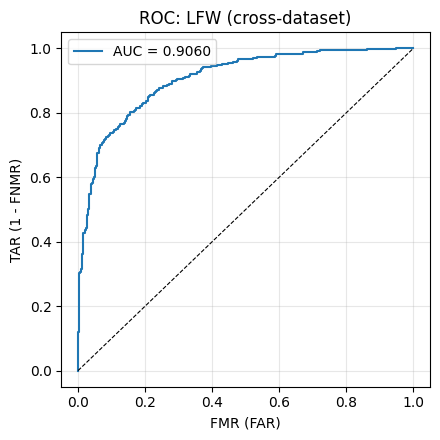

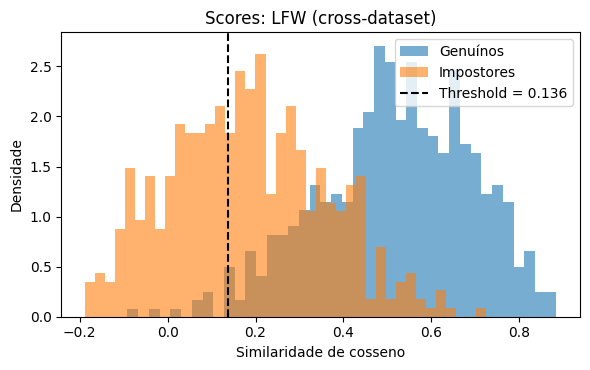

,CFP-FP (teste),LFW (cross)
eer,0.2129,0.1850
auc,0.8644,0.9060
fmr,0.2371,0.5860
fnmr,0.1957,0.0260
tar_at_far_1pct,0.2500,0.3160
accuracy_at_threshold,0.7836,0.6940
threshold,0.1363,0.1363
n_genuine,700.0000,500.0000
n_impostor,700.0000,500.0000


FTA LFW: 0.0


In [27]:
res_lfw, lfw_scores, lfw_labels = evaluate_and_save("lfw_cross", LFW_PROC, lfw_pairs, THRESHOLD, "LFW (cross-dataset)")
display(pd.DataFrame({"CFP-FP (teste)": res_cfp["metrics"], "LFW (cross)": res_lfw["metrics"]}).round(4))
print("FTA LFW:", res_lfw["fta"])

---
# Parte 10: Robustez (Experimento D)

Pergunta: **o que acontece quando a qualidade da imagem piora?** Degradamos as imagens de teste do CFP-FP em **4 níveis** (original, baixa, média, alta) e medimos de novo, com o **mesmo modelo e o mesmo threshold congelado**.

Duas degradações:
- **Blur gaussiano:** borra a imagem (como foco ruim). Quanto maior o `sigma`, mais borrado.
- **Oclusão:** um quadrado preto no centro do rosto (como óculos escuros, máscara ou mão na frente). O parâmetro é a fração do lado da imagem coberta.

A degradação é aplicada **na hora de carregar** a imagem (via `perturb`), sem alterar os arquivos em disco.

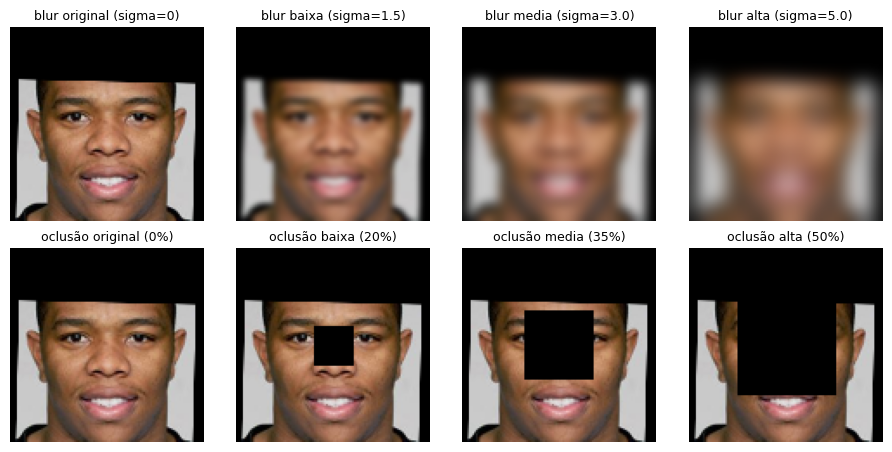

,perturbação,nível,parâmetro,eer,auc,fmr,fnmr,tar_at_far_1pct
0,blur,original,0.00,0.2129,0.8644,0.2371,0.1957,0.2500
1,blur,baixa,1.50,0.2771,0.7859,0.4614,0.1357,0.1257
2,blur,media,3.00,0.3507,0.6998,0.7800,0.0743,0.0543
3,blur,alta,5.00,0.4171,0.6206,0.9514,0.0071,0.0386
4,oclusão,original,0.00,0.2129,0.8644,0.2371,0.1957,0.2500
5,oclusão,baixa,0.20,0.2743,0.8028,0.4014,0.1929,0.1229
6,oclusão,media,0.35,0.3093,0.7571,0.5129,0.1843,0.1000
7,oclusão,alta,0.50,0.3293,0.7287,0.5357,0.1443,0.0557


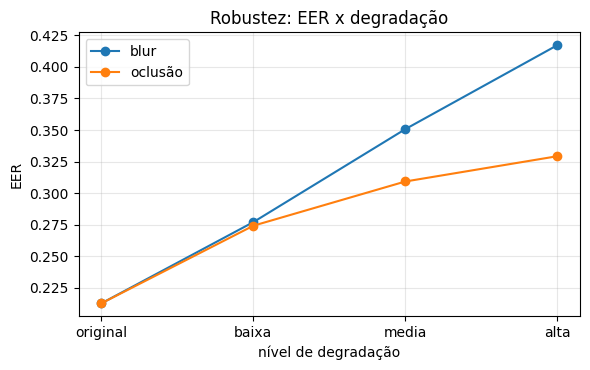

In [28]:
class Blur:
    def __init__(self, sigma): self.sigma = sigma
    def __call__(self, img):
        return img if self.sigma <= 0 else img.filter(ImageFilter.GaussianBlur(self.sigma))

class Occlude:
    """Quadrado preto central com lado = `frac` x lado da imagem."""
    def __init__(self, frac): self.frac = frac
    def __call__(self, img):
        if self.frac <= 0: return img
        img = img.copy(); w, h = img.size
        s = int(round(self.frac * min(w, h))); x0, y0 = (w - s) // 2, (h - s) // 2
        ImageDraw.Draw(img).rectangle([x0, y0, x0 + s, y0 + s], fill=(0, 0, 0))
        return img

LEVELS = ["original", "baixa", "media", "alta"]
(RES_DIR / "robustness").mkdir(exist_ok=True)

# Exemplo visual dos 4 níveis para uma imagem
amostra = Image.open(processed_file(CFP_PROC, test_pairs.amostra_1.iloc[0])).convert("RGB")
show_images([Blur(s)(amostra) for s in BLUR_SIGMAS] + [Occlude(f)(amostra) for f in OCCLUSION_FRACS],
            [f"blur {n} (sigma={s})" for n, s in zip(LEVELS, BLUR_SIGMAS)] + [f"oclusão {n} ({int(f * 100)}%)" for n, f in zip(LEVELS, OCCLUSION_FRACS)], cols=4, size=2.3)

rows = []
for pert, params, cls in (("blur", BLUR_SIGMAS, Blur), ("oclusão", OCCLUSION_FRACS, Occlude)):
    for nome, v in zip(LEVELS, params):
        scores, labels, _ = embed_pairs(model, CFP_PROC, test_pairs, cls(v))
        m = full_metrics(labels, scores, THRESHOLD)
        save_scores(RES_DIR / "robustness" / f"scores_{pert}_{nome}.csv", test_pairs, scores)
        rows.append({"perturbação": pert, "nível": nome, "parâmetro": v, **{k: m[k] for k in ("eer", "auc", "fmr", "fnmr", "tar_at_far_1pct")}})
rob = pd.DataFrame(rows)
rob.to_csv(RES_DIR / "robustness" / "summary.csv", index=False)
display(rob.round(4))

plt.figure(figsize=(6, 3.8))
for pert, gdf in rob.groupby("perturbação", sort=False):
    plt.plot(gdf["nível"], gdf.eer, marker="o", label=pert)
plt.ylabel("EER"); plt.xlabel("nível de degradação"); plt.title("Robustez: EER x degradação"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RES_DIR / "robustness" / "robustness_eer.png", dpi=150); plt.show()

---
# Parte 11: Ablação: o que muda **sem o alinhamento**?

Uma ablação remove (ou troca) **uma** etapa do pipeline para medir sua contribuição. Aqui trocamos o alinhamento facial por um simples **recorte central** nas imagens de **teste**, mantendo o mesmo modelo e o mesmo threshold congelado.

> **Importante para o artigo (limitação):** esta é uma ablação **só na inferência**: o modelo foi treinado com imagens alinhadas e vê, no teste, imagens não alinhadas. Ela mede o quanto o modelo *depende* do alinhamento. Uma ablação mais rigorosa refaria o **treino** também sem alinhamento; se houver tempo, mencione isso como trabalho futuro.

In [29]:
CFP_NOALIGN = PROC_DIR / "cfp_fp_noalign"
test_keys = sorted(set(test_pairs.amostra_1) | set(test_pairs.amostra_2))
process_keys(test_keys, IMAGES_DIR, CFP_NOALIGN, IMAGE_SIZE, detector=None)      # detector=None -> só recorte central

res_abl, _, _ = evaluate_and_save("cfp_fp_noalign", CFP_NOALIGN, test_pairs, THRESHOLD, "CFP-FP (sem alinhamento)", show=False)
comp = pd.DataFrame({"com alinhamento": res_cfp["metrics"], "sem alinhamento": res_abl["metrics"]}).loc[["eer", "auc", "fmr", "fnmr", "tar_at_far_1pct"]]
display(comp.round(4))

processando -> cfp_fp_noalign: 100%|██████████| 1179/1179 [00:02<00:00, 417.82it/s]


,com alinhamento,sem alinhamento
eer,0.2129,0.2729
auc,0.8644,0.7966
fmr,0.2371,0.3871
fnmr,0.1957,0.2114
tar_at_far_1pct,0.2500,0.1486


---
# Parte 12: Análise de erros

O enunciado pede **3 falsos matches** e **3 falsos non-matches**, com as amostras, o score, o threshold e uma **hipótese técnica** para cada erro.

- **Falso match:** par de **pessoas diferentes** que o sistema aceitou (os impostores com **maior** score).
- **Falso non-match:** par da **mesma pessoa** que o sistema rejeitou (os genuínos com **menor** score).

A célula mostra os casos; **a hipótese técnica é você quem escreve** olhando as imagens. Perguntas que ajudam: a pose é muito diferente (frontal × perfil)? A foto está borrada ou escura? Há óculos, chapéu, barba, maquiagem? As duas pessoas têm aparência parecida (mesma idade, sexo, etnia, cabelo)? O detector falhou e foi usado o recorte central?

,erro,amostra_1,amostra_2,score,threshold
1094,falso match,457/frontal/03.jpg,477/profile/01.jpg,0.4696,0.1363
537,falso match,427/frontal/10.jpg,404/profile/04.jpg,0.4616,0.1363
637,falso match,442/frontal/04.jpg,413/profile/04.jpg,0.4587,0.1363
803,falso non-match,465/frontal/09.jpg,465/profile/03.jpg,-0.2408,0.1363
188,falso non-match,427/frontal/09.jpg,427/profile/03.jpg,-0.1977,0.1363
786,falso non-match,463/frontal/06.jpg,463/profile/03.jpg,-0.1962,0.1363


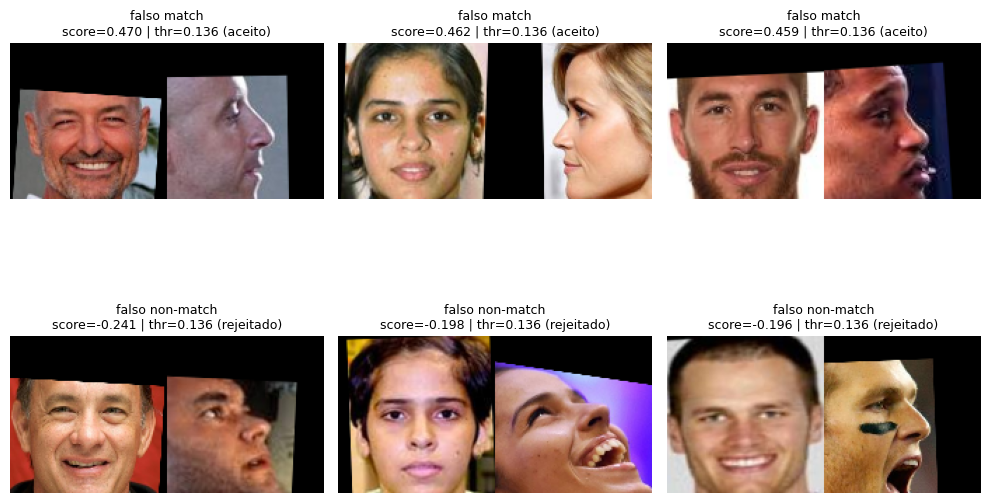

In [30]:
def error_cases(pairs, scores, thr, n=3):
    df = pairs.reset_index(drop=True).assign(score=scores)
    fm  = df[df.tipo == "impostor"].sort_values("score", ascending=False).head(n).assign(erro="falso match")
    fnm = df[df.tipo == "genuine"].sort_values("score").head(n).assign(erro="falso non-match")
    cases = pd.concat([fm, fnm]).assign(threshold=thr)
    return cases[["erro", "amostra_1", "amostra_2", "score", "threshold"]]

cases = error_cases(test_pairs, cfp_scores, THRESHOLD)
cases.to_csv(RES_DIR / "cfp_fp_test" / "errors.csv", index=False)
display(cases.round(4))

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, (_, r) in zip(axes.ravel(), cases.iterrows()):
    a = read_rgb(processed_file(CFP_PROC, r.amostra_1)); b = read_rgb(processed_file(CFP_PROC, r.amostra_2))
    ax.imshow(np.hstack([a, b])); ax.axis("off")
    aceito = "aceito" if r.score >= r.threshold else "rejeitado"
    ax.set_title(f"{r.erro}\nscore={r.score:.3f} | thr={r.threshold:.3f} ({aceito})", fontsize=9)
plt.tight_layout(); plt.savefig(RES_DIR / "cfp_fp_test" / "errors.png", dpi=150); plt.show()

**Para preencher no artigo (um bloco por caso):**

| Caso | Score | Threshold | O que você observa nas imagens | Hipótese técnica |
|---|---|---|---|---|
| Falso match 1 | | | | |
| Falso match 2 | | | | |
| Falso match 3 | | | | |
| Falso non-match 1 | | | | |
| Falso non-match 2 | | | | |
| Falso non-match 3 | | | | |

---
# Parte 13: Eficiência computacional e tabela final

O enunciado pede, para cada modelo: **número de parâmetros, tamanho do modelo, tempo de inferência e hardware**. Medimos o tempo para **uma imagem** (média de várias execuções, depois de algumas execuções de "aquecimento").

In [31]:
def model_info(model, ckpt_path, runs=INFERENCE_RUNS):
    params = sum(p.numel() for p in model.parameters())
    size_mb = os.path.getsize(ckpt_path) / 1e6
    x = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    model.eval()
    with torch.no_grad():
        for _ in range(10): model(x)                       # aquecimento (a 1ª execução é sempre mais lenta)
        if DEVICE.type == "cuda": torch.cuda.synchronize() # espera a GPU terminar (ela é assíncrona)
        t0 = time.perf_counter()
        for _ in range(runs): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) / runs * 1000
    hw = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else (platform.processor() or "CPU")
    return {"num_params": int(params), "model_size_mb": round(size_mb, 2), "inference_ms_per_image": round(ms, 3), "hardware": hw}

eff = model_info(model, CKPT_PATH)
json.dump(eff, open(RES_DIR / "efficiency.json", "w"), indent=2)
print(eff)

{'num_params': 24558144, 'model_size_mb': 98.56, 'inference_ms_per_image': 5.617, 'hardware': 'NVIDIA GeForce RTX 3050 Ti Laptop GPU'}


### Tabela padronizada (modelo para a seção de resultados do artigo)

In [32]:
def fmt(x, nd=4):
    return "-" if x is None else (f"{x:.{nd}f}" if isinstance(x, float) else str(x))

tabela = pd.DataFrame({
    "Informação": ["Modalidade", "Dataset", "CNN", "Pré-treinamento", "Nº de parâmetros", "Dimensão do embedding", "Matching",
                   "Threshold (definido na validação)", "EER", "AUC", "FMR", "FNMR", "TAR@FAR=1%", "FTA", "Tempo de inferência (ms/img)", "Tamanho do modelo (MB)", "Hardware"],
    "CFP-FP (teste)": ["Face", "CFP-FP", "ResNet50", "ImageNet-1k", f"{eff['num_params']:,}", EMBEDDING_DIM, "Cosseno", fmt(THRESHOLD),
                       fmt(res_cfp["metrics"]["eer"]), fmt(res_cfp["metrics"]["auc"]), fmt(res_cfp["metrics"]["fmr"]), fmt(res_cfp["metrics"]["fnmr"]),
                       fmt(res_cfp["metrics"]["tar_at_far_1pct"]), fmt(res_cfp["fta"]), eff["inference_ms_per_image"], eff["model_size_mb"], eff["hardware"]],
    "LFW (cross-dataset)": ["Face", "LFW", "ResNet50", "ImageNet-1k", f"{eff['num_params']:,}", EMBEDDING_DIM, "Cosseno", fmt(THRESHOLD) + " (congelado)",
                            fmt(res_lfw["metrics"]["eer"]), fmt(res_lfw["metrics"]["auc"]), fmt(res_lfw["metrics"]["fmr"]), fmt(res_lfw["metrics"]["fnmr"]),
                            fmt(res_lfw["metrics"]["tar_at_far_1pct"]), fmt(res_lfw["fta"]), eff["inference_ms_per_image"], eff["model_size_mb"], eff["hardware"]],
})
tabela.to_csv(RES_DIR / "tabela_padronizada.csv", index=False)
display(tabela)
print("\nTudo que o notebook gerou está em:", WORK_DIR)
for p in sorted(RES_DIR.rglob("*")):
    if p.is_file(): print(" ", p.relative_to(WORK_DIR))

,Informação,CFP-FP (teste),LFW (cross-dataset)
0,Modalidade,Face,Face
1,Dataset,CFP-FP,LFW
2,CNN,ResNet50,ResNet50
3,Pré-treinamento,ImageNet-1k,ImageNet-1k
4,Nº de parâmetros,"24,558,144","24,558,144"
5,Dimensão do embedding,512,512
6,Matching,Cosseno,Cosseno
7,Threshold (definido na validação),0.1363,0.1363 (congelado)
8,EER,0.2129,0.1850
9,AUC,0.8644,0.9060



Tudo que o notebook gerou está em: c:\Users\gusta\Desktop\Projeto_Biometria\saidas
  results\cfp_fp_noalign\metrics.json
  results\cfp_fp_noalign\scores.csv
  results\cfp_fp_test\distributions.png
  results\cfp_fp_test\errors.csv
  results\cfp_fp_test\errors.png
  results\cfp_fp_test\metrics.json
  results\cfp_fp_test\roc.png
  results\cfp_fp_test\scores.csv
  results\distributions.png
  results\efficiency.json
  results\lfw_cross\distributions.png
  results\lfw_cross\metrics.json
  results\lfw_cross\roc.png
  results\lfw_cross\scores.csv
  results\metrics.json
  results\preprocess_examples.png
  results\robustness\robustness_eer.png
  results\robustness\scores_blur_alta.csv
  results\robustness\scores_blur_baixa.csv
  results\robustness\scores_blur_media.csv
  results\robustness\scores_blur_original.csv
  results\robustness\scores_oclusão_alta.csv
  results\robustness\scores_oclusão_baixa.csv
  results\robustness\scores_oclusão_media.csv
  results\robustness\scores_oclusão_original.c

---
# Checklist final

**Do código (já feito por este notebook):**
- [x] Divisão por **identidade** (verificada no código)
- [x] Threshold definido **só na validação** e congelado
- [x] Embedding + matching por cosseno (sem classificador direto na avaliação)
- [x] Métricas: FMR, FNMR, EER, AUC, ROC, TAR@FAR=1%, distribuições, FTA, parâmetros, tempo, tamanho
- [x] Cross-dataset sem novo fine-tuning
- [x] Robustez em 4 níveis, ablação e análise de erros

**O que ainda depende de você / da dupla:**
- [ ] **Combinar com a outra dupla** que os `test_pairs.csv` (CFP-FP) e `lfw_test_pairs.csv` sejam **idênticos** nas duas
- [ ] Registrar a CNN escolhida com o professor
- [ ] Escrever a **hipótese técnica** de cada erro (Parte 12)
- [ ] Declarar no artigo: pesos de **ImageNet** (sem vazamento de identidades de faces); LFW já alinhado; protocolo 6/2/2 folds (e não o 10-fold cross-validation); ablação apenas na inferência; seed 42; hardware usado
- [ ] Se sobrar tempo: repetir o treino com as seeds 123 e 2026 (`SEED = 123`, `RETRAIN = True`) e reportar média ± desvio
- [ ] Exportar o código para os `.py` do repositório (`model.py`, `train.py`, `evaluate.py`...) e preencher o README